In [165]:
import pandas as pd
import matplotlib.pyplot as plt
import random
import matplotlib.colors as mcolors

In [166]:
documents = pd.read_csv("top_topic_documents.csv", index_col = 0)
documents.head()

,basename,year,topic,score
0,ra_10924_2016,2016,14,0.551755
1,ra_10923_2016,2016,3,0.405266
2,ra_10925_2017,2017,4,0.901010
3,ra_10926_2017,2017,11,0.659243
4,ra_10927_2017,2017,10,0.513400


In [167]:
topics = pd.read_csv("top_topics.csv", index_col=0)
print(f"total topics: {len(topics)}")
topics.head()

total topics: 20


,topic,word,prob,labels
0,0,product,0.026058,"marking, distributor, trademark, engine, manuf..."
1,1,education,0.038444,"readiness, learner, instructional material, li..."
2,2,campus,0.063781,"section asset real personal personnel, progres..."
3,3,barangay,0.069155,"san_antonio, sitio, alvarez_speaker_of_the_hou..."
4,4,grantee,0.042825,"extreme_emergency_or_calamity ntc issue, equiv..."


In [168]:
documents.query('year == 2016')

,basename,year,topic,score
0,ra_10924_2016,2016,14,0.551755
1,ra_10923_2016,2016,3,0.405266


In [169]:
df = pd.merge(documents, topics, on=['topic'], how='inner')
df

,basename,year,topic,score,word,prob,labels
0,ra_10924_2016,2016,14,0.551755,fund,0.020654,"equipment spare, equipment spare part, rent, s..."
1,ra_10923_2016,2016,3,0.405266,barangay,0.069155,"san_antonio, sitio, alvarez_speaker_of_the_hou..."
2,ra_10925_2017,2017,4,0.901010,grantee,0.042825,"extreme_emergency_or_calamity ntc issue, equiv..."
3,ra_10926_2017,2017,11,0.659243,grantee,0.055234,ntc not_unreasonably_withhold delay_the_grant ...
4,ra_10927_2017,2017,10,0.513400,person,0.035447,"affirmation, conspire, signatory, investigatio..."
...,...,...,...,...,...,...,...
990,ra_11929_2022,2022,6,0.802915,city,0.060811,code amend develop_plans_and_strategies approv...
991,ra_11930_2022,2022,10,0.345237,person,0.035447,"affirmation, conspire, signatory, investigatio..."
992,ra_11931_2022,2022,11,0.953956,grantee,0.055234,ntc not_unreasonably_withhold delay_the_grant ...
993,ra_11932_2022,2022,12,0.605405,national,0.021932,"serve unexpired, serve unexpired term, reading..."


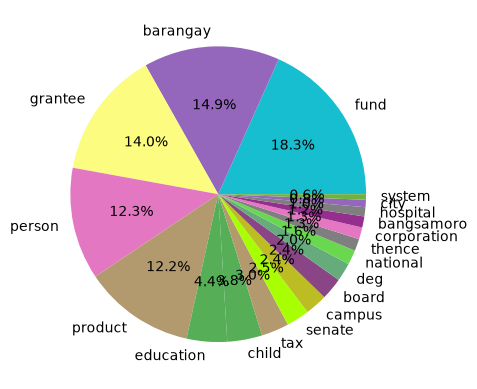

In [174]:
topic_labels = df['word'].unique()
topic_colors = {}
i = 0
color_list = list(mcolors.TABLEAU_COLORS) + list(mcolors.XKCD_COLORS)
random_colors = [random.randint(1, len(topics)) for _ in range(len(topics))]
for l in topic_labels:
    topic_colors[l] = color_list[random_colors[i]]
    i = i + 1
counts = df['word'].value_counts()
fig, ax = plt.subplots(1, 1)
labels = df['word'].unique()
ax.pie(counts, labels=labels, colors=[topic_colors[key] for key in labels], autopct='%1.1f%%')

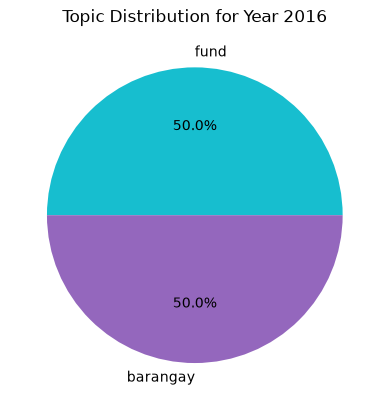

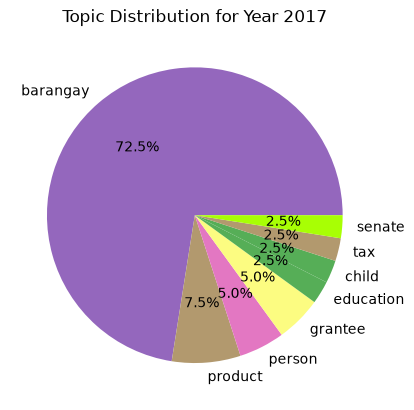

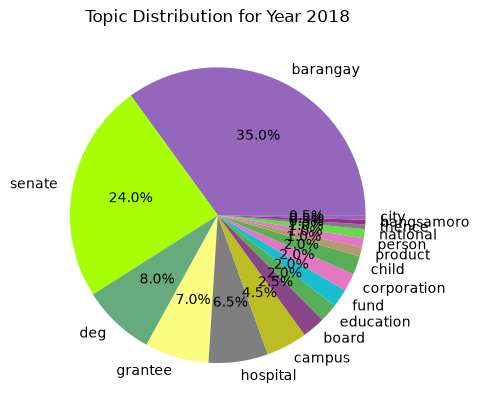

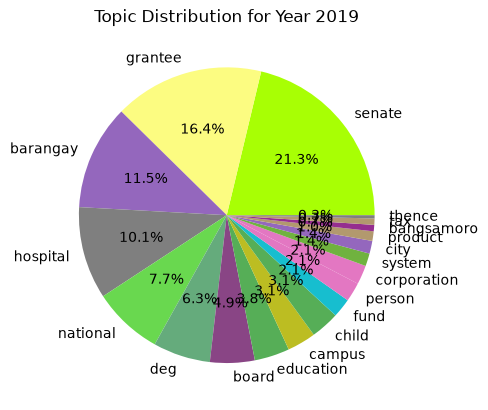

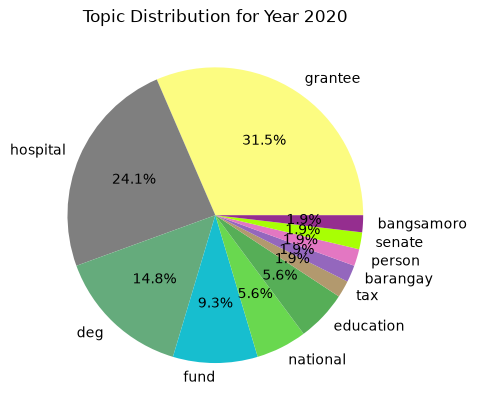

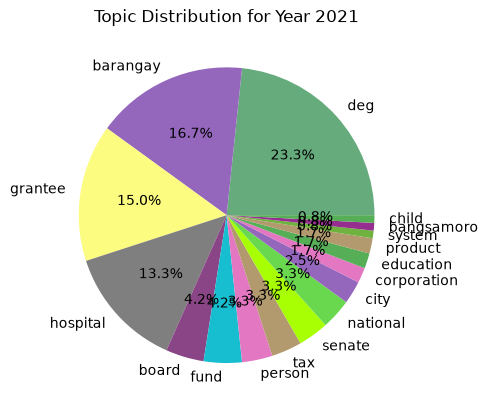

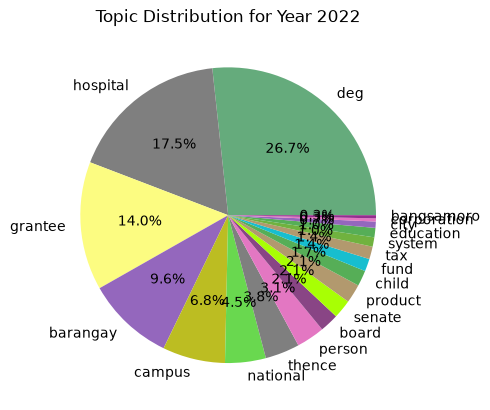

In [175]:
for year in df['year'].unique():
    period = df.query(f'year == {year}')
    counts = period['word'].value_counts()
    labels = counts.index.tolist()
    x = counts.values.tolist()
    fig, ax = plt.subplots(1, 1)
    ax.pie(counts, labels=labels, colors=[topic_colors[key] for key in labels], autopct='%1.1f%%')
    ax.set_title(f'Topic Distribution for Year {year}')
    # counts = period['word'].value_counts()
    # counts.plot(kind='pie', autopct='%1.1f%%')
    # plt.title(f'Topic Distribution for Year {year}')
    # plt.show()
